First 5 rows of the dataset: 
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset shape: 
(1000, 8)

Number of math scores values:  1000

IQR Method
Q1:  57.0
Q3:  77.0
IQR:  20.0
Lower limit:  27.0
Upp

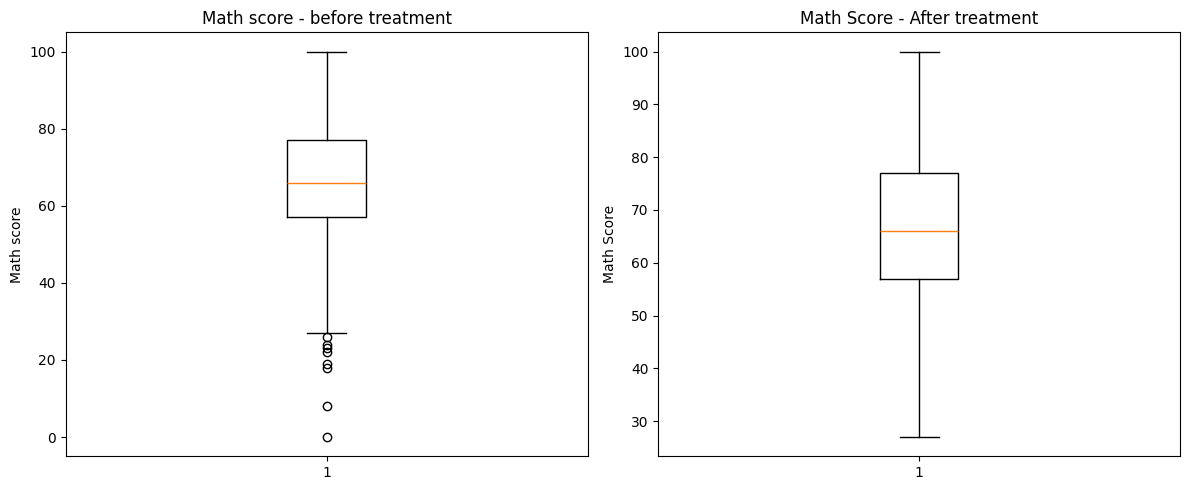

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("StudentsPerformance.csv")
print("First 5 rows of the dataset: ")
print(df.head())
print("\nDataset shape: ")
print(df.shape)
data = df["math score"].dropna()
print("\nNumber of math scores values: ", len(data))
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR
print("\nIQR Method")
print("Q1: ", Q1)
print("Q3: ", Q3)
print("IQR: ", IQR)
print("Lower limit: ", lower_limit)
print("Upper limit: ", upper_limit)
iqr_outliers = df[
    (df["math score"]<lower_limit) |
    (df["math score"]>upper_limit)
]
print("Number of IQR outliers: ", len(iqr_outliers))
mean = data.mean()
std = data.std()
df["Z_score"] = (df["math score"]-mean)/std

z_outliers = df[abs(df["Z_score"])>3]
print("\nZ-Score Method")
print("Mean: ", mean)
print("Standard Deviation: ", std)
print("Number of Z-score outliers: ", len(z_outliers))


print("\nOutliers")
if len(iqr_outliers) > 0:
  print(iqr_outliers[["math score"]])
else:
  print("No IQR outliers found.")
print("\n Z-score outliers")
if(len(z_outliers)>0):
  print(z_outliers[["math score", "Z_score"]])
else:
  print("No z-score outliers found.")

df["math_score_treated"] = df["math score"].clip(
    lower = lower_limit,
    upper = upper_limit
)
print("Treatment method: capping using IQR limits")

print("\nbefore treament")
print(df["math score"].describe())
print("\nafter treatment")
print(df["math_score_treated"].describe())

comparison = df[
    ["math score" , "math_score_treated"]
]
print(comparison.head(20))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math score - before treatment")
plt.ylabel("Math score")
plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After treatment")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()